# Multimodal Music Analysis

The target of this project is the implementation of a complete pipeline for extracting knowledge from music data by combining two different modalities: **Audio** and **Text**. The project is split into two parts:  
1. Preprocessing of the data, generation of embeddings and researching analysis.
2. Classification, Fusion and Evaluation.  
  
This notebook contains the implementation of part 1.


Requirements:

In [ ]:
%pip install seaborn
%pip install datasets
%pip install matplotlib
%pip install vaderSentiment
%pip install kneed
%pip install contractions
%pip install pyspellchecker
%pip install scikit-learn
%pip install pandas
%pip install wordcloud
%pip install tensorflow

## 1. Data Collection


In [1]:
import pandas as pd
import os

import numpy as np
import tensorflow as tf
import sklearn

import matplotlib.pyplot as plt

- Run the code in the next sections for pre-processing the data 
- In case the file already exists, the next sections are skipped automatically

In [2]:
def keep_top_n(df, column, n):
    top_values = df[column].value_counts().head(n).index.to_list()
    filtered_df = df[df[column].isin(top_values)]
    return filtered_df

In [3]:
def create_lyrics_df(target_ids, path='data/processed_lyrics'):
    # --- Filtering the lyrics of the songs ---
    lyrics_folder = path

    lyrics_data = []

    for filename in os.listdir(lyrics_folder):
        if filename.endswith('.txt'):
            song_id = filename.replace('.txt', '')
            
            if song_id in target_ids:
                file_path = os.path.join(lyrics_folder, filename)
                
                with open(file_path, 'r', encoding='utf-8') as f:
                    lyrics_text = f.read()
                
                lyrics_data.append({
                    'id': song_id,
                    'lyrics': lyrics_text
                })

    lyrics_df = pd.DataFrame(lyrics_data)
    return lyrics_df

In [4]:
def merge_dataframes(dfs, merge_on):
    merged_df = dfs[0]

    for df in dfs[1:]:
        merged_df = pd.merge(merged_df, df, on=merge_on)

    return merged_df


In [5]:

def collect_data():
    # --- Importing the datasets ---
    genres_df = pd.read_csv('data/id_genres.csv', sep='\t') 
    information_df = pd.read_csv('data/id_information.csv', sep='\t')
    tags_df = pd.read_csv('data/id_tags.csv', sep='\t')
    mfcc_stats_df = pd.read_csv('data/id_mfcc_stats.tsv', sep='\t').dropna()

    # ---- Group mfcc stats in one column for better data ----
    mfcc_stats_df = mfcc_stats_df.copy()

    mfcc_columns = [col for col in mfcc_stats_df.columns if 'mfcc' in col.lower() or 'cov' in col.lower()]

    mfcc_stats_df['audio_stats'] = mfcc_stats_df[mfcc_columns].values.tolist()

    audio_stats_df = mfcc_stats_df.drop(columns=mfcc_columns)

    # --- Filtering the genres dataset to only include the top n most common genres ---
    filtered_genres_df = keep_top_n(genres_df, "genres", 5)

    # --- Create dataframe with the lyrics of the songs ---
    lyrics_df = create_lyrics_df(target_ids=set(filtered_genres_df['id'].astype(str)))

    # --- Merging dataframes ---
    dataframes = [filtered_genres_df, information_df, tags_df, audio_stats_df, lyrics_df]
    df = merge_dataframes(dataframes, "id")

    # --- Handling missing and duplicate values ---
    df = df[df['lyrics'].notna()]
    df = df[df['lyrics'].str.strip() != '']
    df = df[df['genres'].notna()]
    df = df[df['genres'].str.strip() != '']
    df = df.drop_duplicates(subset='id', keep='first')

    return df
    

In [6]:
final_df_path = "data/final_data.pkl"
if (os.path.isfile(path=final_df_path)):
    data = pd.read_pickle(final_df_path,)
else:
    data = collect_data()
    data = data.drop(columns=["artist", "album_name"])
    data.to_pickle(final_df_path)
    
data.head()

,id,genres,song,tags,audio_stats,lyrics
0,0009fFIM1eYThaPg,pop,Rain on Me,"pop,british,female vocalists,dance,cheryl cole","[23.622419357299805, -14.43531894683838, -7.96...",sunni day get nowher hide cloud sky pretend ge...
1,00P2bHdWFkghmDqz,soul,Tell Me a Tale,"fip,soul","[23.64550018310547, -2.017793893814087, -7.855...",tell tale alway sing song alway tell stori rea...
2,00XWljDxNBgBKEEA,pop,Y cómo es él?,"jose luis perales,spanish,pop","[21.851207733154297, -14.782770156860352, -0.7...",look eye would swear someth new tell start wom...
3,00b6fV3nx5z2b8Ls,pop,ABC,"glee,pop,cover,glee cast","[23.93406867980957, -16.48297119140625, -5.680...",buhbuh buh buhbuh buhbuh buh buhbuh go school ...
4,013QDoTqbexEwkHr,pop,Patience,"pop,george michael,6 of 10 stars","[20.773107528686523, 0.3843250572681427, 2.080...",like convers noon stop breath imagin god alrea...


## 2. Feature Extraction

### **Audio Embeddings**

### Autoencoder
Creating and training a simple Autoencoder to compress the vector of the audio embedding to a vector with fewer dimensions.

In [69]:
class Autoencoder(tf.keras.Model):
    def __init__(self, input_dim, encoding_dim=32):
        super(Autoencoder, self).__init__()

        layers = tf.keras.layers

        self.encoder = tf.keras.Sequential([
            layers.Input(shape=(input_dim,)),
            layers.Dense(64, activation='relu'),
            layers.BatchNormalization(),
            layers.Dropout(0.2),
            layers.Dense(encoding_dim, activation='relu')
        ])

        self.decoder = tf.keras.Sequential([
            layers.Input(shape=(encoding_dim,)),
            layers.Dense(64, activation='relu'),
            layers.BatchNormalization(),
            layers.Dropout(0.2),
            layers.Dense(input_dim, activation='linear')
        ])

    def call(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

In [70]:
from sklearn.preprocessing import StandardScaler
from keras.callbacks import EarlyStopping, TensorBoard


'''
Function to train the autoencoder.
Arguments:  - scaled audio_stats from the dataframe ready for training
            - optional: hyperparameters for the training
Returns:    - training history for visualization
            - the trained autoencoder
'''
def autoencoder_training(audio_stats, encoding_dim=32, optimizer="adam", loss="mse",
                         epochs=100, batch_size=32, early_stopping_epoch=20):

    input_dim = audio_stats.shape[1]

    # --- autoencoder ---
    autoencoder = Autoencoder(input_dim, encoding_dim)

    autoencoder.compile(optimizer=optimizer, loss=loss)

    # --- autoencoder training ---
    early_stopping = EarlyStopping(
        monitor='val_loss',
        patience=early_stopping_epoch,
        restore_best_weights=True
    )

    training = autoencoder.fit(audio_stats, audio_stats,
                        epochs=epochs,
                        batch_size=batch_size,
                        shuffle=True,
                        callbacks=[early_stopping],
                        validation_split=0.2)

    return training, autoencoder    


In [71]:
# --- Extraction the audio embeddings from the audio stats column ---
audio_embeddings = np.array(data["audio_stats"].to_list(), dtype=float)
scaler = StandardScaler()
audio_embed_train = scaler.fit_transform(audio_embeddings)

training, autoencoder = autoencoder_training(audio_stats=audio_embed_train)



Epoch 1/100
290/290 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.7395 - val_loss: 0.5693
Epoch 2/100
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.5291 - val_loss: 0.4580
Epoch 3/100
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4466 - val_loss: 0.4132
Epoch 4/100
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4026 - val_loss: 0.3782
Epoch 5/100
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3752 - val_loss: 0.3587
Epoch 6/100
290/290 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3526 - val_loss: 0.3404
Epoch 7/100
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3351 - val_loss: 0.3247
Epoch 8/100
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3204 - val_loss: 0.3108
Epoch 9/100
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3087 - val_loss: 0.3078
Epoch 10/100
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3010 - val_loss: 0.3035
Epoch 11/100
290/290 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2955 - val_loss: 0.2930
Epoch 12/100
290/290 ━━━━━━━━━━━━━━━━━━━━

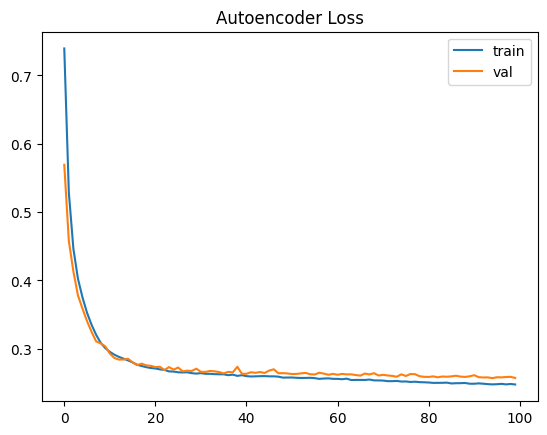

In [72]:
plt.plot(training.history['loss'], label='train')
plt.plot(training.history['val_loss'], label='val')
plt.legend()
plt.title("Autoencoder Loss")
plt.show()

In [73]:
# --- final compresses audio embeddings with 32 dim ---

autoenc_audio_embeddings = autoencoder.encoder.predict(audio_embed_train)
print(autoenc_audio_embeddings.shape)

362/362 ━━━━━━━━━━━━━━━━━━━━ 0s 545us/step
(11571, 32)


### Principal Component Analysis (PCA)

In [15]:
from sklearn.decomposition import PCA

audio_embeddings = np.array(data["audio_stats"].tolist(), dtype=float)
scaler = StandardScaler()
audio_scaled = scaler.fit_transform(audio_embeddings)


pca = PCA(n_components=0.95)  # keep 95% variance
pca_audio_embeddings = pca.fit_transform(audio_scaled)

pca_audio_embeddings.shape

(11571, 78)

### Comparison between PCA and Autoencoder

In [ ]:
from sklearn.manifold import TSNE

# --- t-SNE visualization of the PCA and autoencoder embeddings ---
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne_pca = tsne.fit_transform(pca_audio_embeddings)
X_tsne_auto = tsne.fit_transform(autoenc_audio_embeddings)


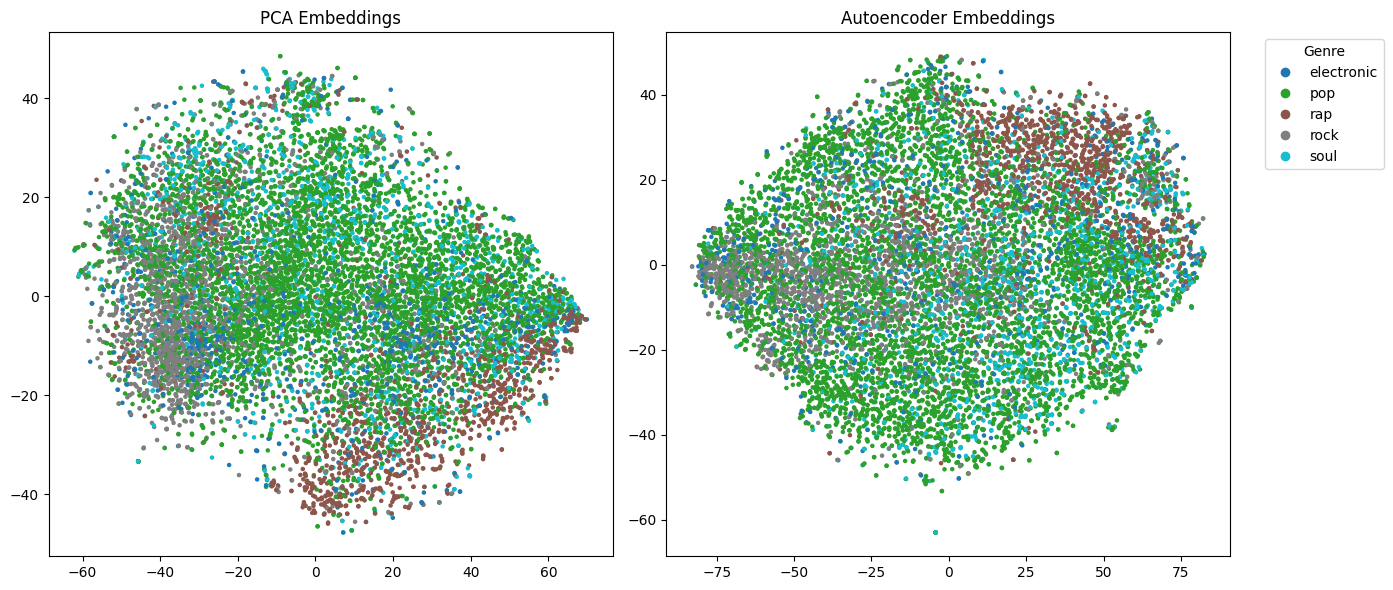

In [74]:
# --- color the points by genre ---
categories = data['genres'].astype('category')
y = categories.cat.codes
genre_names = categories.cat.categories

# --- scatter plot of the t-SNE embeddings colored by genre ---
fig, axes = plt.subplots(1,2, figsize=(14,6))

scatter1 = axes[0].scatter(X_tsne_pca[:,0], X_tsne_pca[:,1], c=y, cmap='tab10', s=5)
axes[0].set_title("PCA Embeddings")

scatter2 = axes[1].scatter(X_tsne_auto[:,0], X_tsne_auto[:,1], c=y, cmap='tab10', s=5)
axes[1].set_title("Autoencoder Embeddings")

handles, _ = scatter1.legend_elements()
axes[1].legend(handles, genre_names, title="Genre", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()

plt.show()

From the visualization of the audio embeddings (both PCA and Autoencoder-based), there is no clear separation between most music genres, as the data points largely overlap. Some genres like Rock and Rap show slightly more distinct patterns, while others such as Pop, Electronic, and Soul appear more mixed.

In the next part, we will introduce classifiers to better capture the underlying structure of the data and improve genre discrimination.

## 3. Visualization and Analysis

### **Wordcloud**
Analyzing in wordclouds the most frequent words used in the tags of **rap** and **rock** songs.

In [75]:
from wordcloud import WordCloud


def create_wordcloud(text, title, color='white'):

    wordcloud = WordCloud(width=800, height=400, background_color=color).generate(text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(title)
    plt.show()

In [76]:
# Preparing the data for word cloud generation
wordcloud_df = data[['genres','tags']]
rap_df = wordcloud_df[wordcloud_df['genres'] == 'rap']
rock_df = wordcloud_df[wordcloud_df['genres'] == 'rock'] 

rap_tags = " ".join(rap_df['tags'].dropna())
rock_tags = " ".join(rock_df['tags'].dropna())

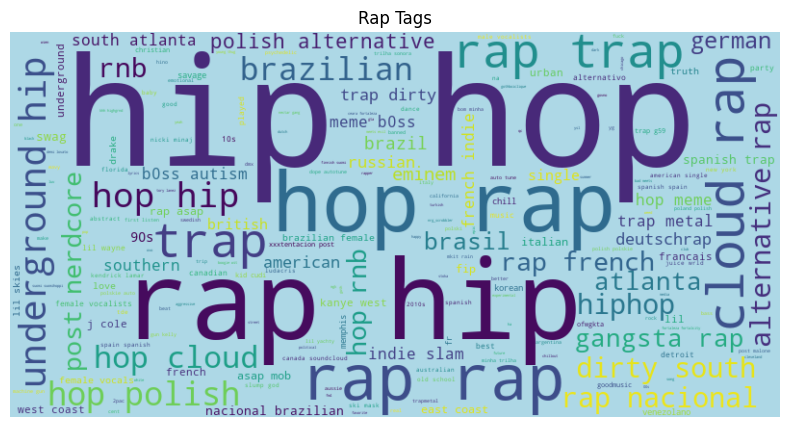

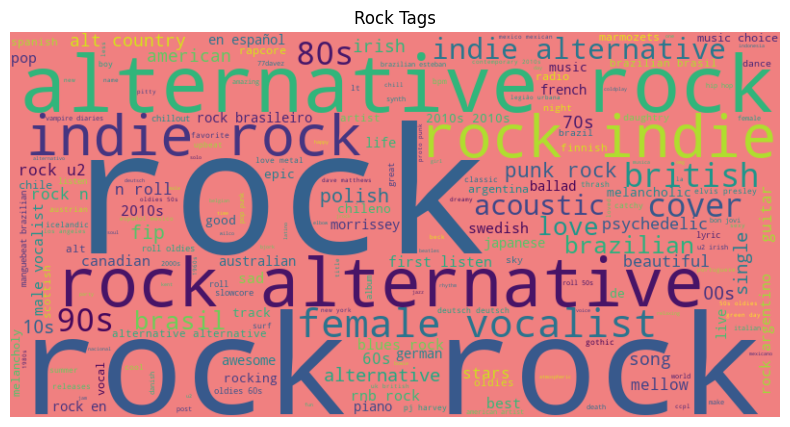

In [77]:
# Creating wordclouds for rap and rock genres
create_wordcloud(rap_tags, 'Rap Tags', color='lightblue')
create_wordcloud(rock_tags, 'Rock Tags', color='lightcoral')


### **Bar Chart**

Present the 10 most appeared tags grouped by the genre of the songs

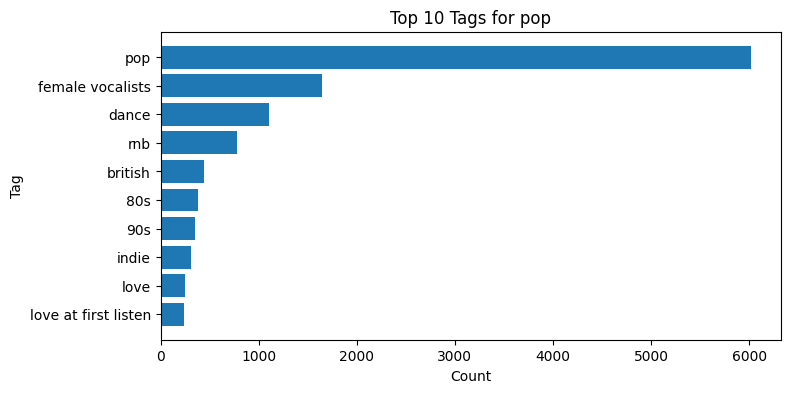

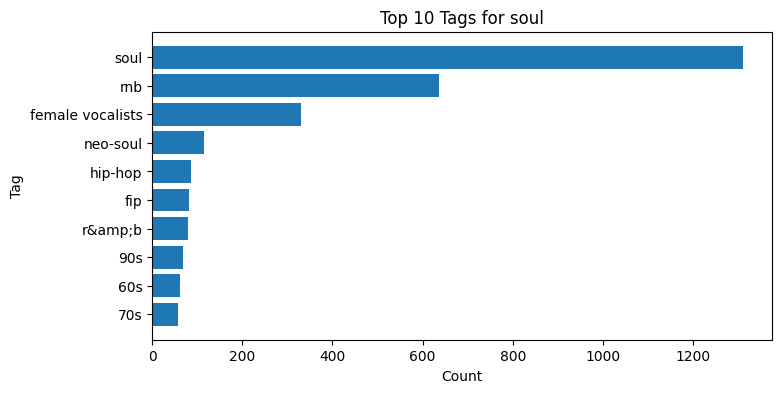

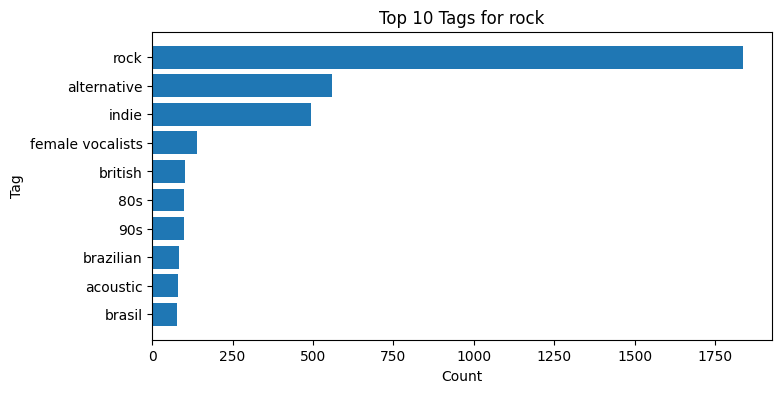

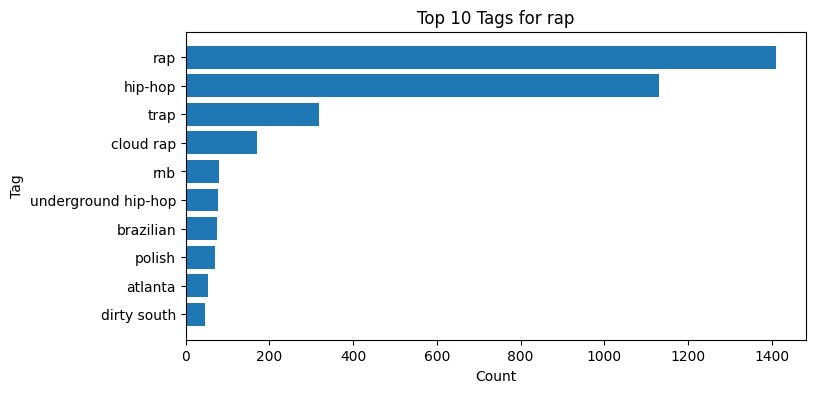

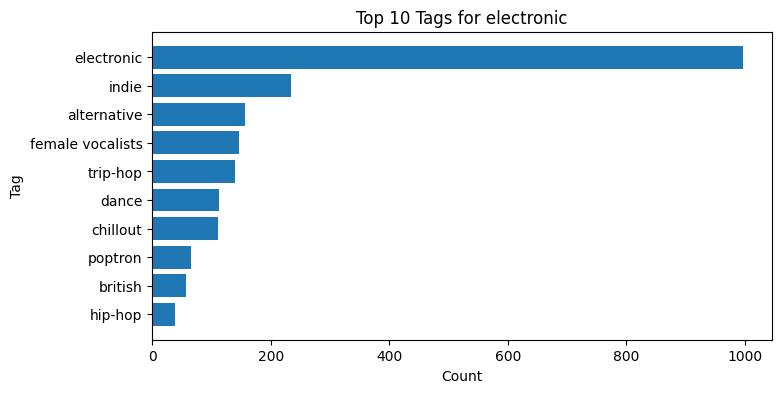

In [82]:
from collections import Counter
import matplotlib.pyplot as plt

data['tags_list'] = data['tags'].fillna('').apply(
    lambda x: [tag.strip() for tag in x.split(',') if tag.strip() != '']
)

for genre in data['genres'].unique():
    subset = data[data['genres'] == genre]

    all_tags = [tag for tags in subset['tags_list'] for tag in tags]

    tag_counts = Counter(all_tags)
    top_tags = tag_counts.most_common(10)

    tags, counts = zip(*top_tags)

    plt.figure(figsize=(8, 4))
    plt.barh(tags, counts)
    plt.gca().invert_yaxis()
    plt.title(f"Top 10 Tags for {genre}")
    plt.xlabel("Count")
    plt.ylabel("Tag")
    plt.show()